# 19 · Full-FOV — ảnh bị cắt mất bao nhiêu, và có đáng dựng lại không

Nhánh **2b** của kế hoạch (`sleepy-puzzling-harbor.md`).

## Phát hiện khi đọc lại pipeline: có **hai** lần cắt chồng lên nhau

### Lần 1 — `04a_preprocess_images.ipynb` cell 8, lúc tạo shard

```python
if SHORTEST_EDGE:                      # True voi RAD-DINO
    s = STORE_SIZE / min(w, h)         # scale theo canh NGAN
    im = im.resize((round(w*s), round(h*s)), BICUBIC)
    im = im.crop(center STORE x STORE) # <-- CAT, thong tin MAT VINH VIEN
```

Cạnh ngắn được đưa về `STORE_SIZE` rồi cắt vuông ⇒ **cạnh dài bị xén**. Phim ngực thường ở dạng
**đứng**, nên phần bị xén là **đỉnh phổi** và **góc sườn hoành**.

### Lần 2 — `C5` của nb16, lúc train/eval

`CenterCrop(518)` từ `STORE_SIZE` ⇒ xén thêm một viền mỏng mỗi bên.

⚠ `STORE_SIZE` **đo từ shard thật** ở `C1`, không lấy từ tên thư mục: `04a` dùng
`int(round(518 × 1.08)) = ` **`559`**, còn `cxr_560_shards` chỉ là số làm tròn.

### Vì sao điều này đáng quan tâm

`Pleural_Other` sống ở **rìa màng phổi** và **góc sườn hoành**. `Fracture` sống ở **xương sườn
dưới** và **xương đòn**. Cả hai đều nằm đúng vùng bị lần cắt 1 loại bỏ.

Đây là một cơ chế **cụ thể** cho giả thuyết nút thắt ngoại vi — và mạnh hơn giả thuyết ban đầu,
vì phần mất lớn nằm ở khâu **tiền xử lý**, chỗ không transform nào ở lúc train cứu lại được.

## Ba bước

| | làm gì | chi phí |
|---|---|---|
| `F1` | **Đo** phần FOV đã mất, từ header ảnh gốc trên Drive | ~2–5 ph, CPU |
| `F2` | Sàng rẻ — **đã nằm ở `17_r0_baseline_optimization.ipynb` `C5`** | (không lặp lại) |
| `F3` | Dựng lại shard bằng **letterbox** giữ trọn FOV, rồi train lại | ~2 h + ~4 h GPU |

## ⚠ `F2` âm **không** bác bỏ giả thuyết

`F2` (ở nb17) chỉ thu hồi được viền `21px` của **lần cắt 2**. Phần mất lớn nằm ở **lần cắt 1** và
chỉ `F3` mới chạm tới. Ghi trước để một kết quả âm ở nb17 không đóng nhầm câu hỏi này.

**`F1` là thứ quyết định `F3` có đáng làm không** — và nó rẻ.

## C0 · Config + **cổng quyết định khoá trước**

Ngưỡng viết ra trước khi đo, để con số đo được không tự bào chữa cho quyết định.

In [1]:
import os, io, json, time, math, pickle, random
import numpy as np, pandas as pd
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from tqdm.auto import tqdm

try:
    from google.colab import drive
    drive.mount('/content/drive'); DATA_DIR = '/content/drive/MyDrive/MIMIC_CXR/planB_out'
except Exception:
    DATA_DIR = '.'
OUT_DIR   = os.path.join(DATA_DIR, 'cohort_v2')
DRIVE_IMG = '/content/drive/MyDrive/MIMIC_CXR/mimic-cxr-jpg-2.1.0.physionet.org/files'
SHARD_DIR = os.path.join(DATA_DIR, 'cxr_560_shards')            # shard HIEN HANH — chi doc
SHARD_FULL = os.path.join(DATA_DIR, 'cxr_559_fullfov_shards')  # shard MOI: KHONG center-crop
SC_DIR    = os.path.join(DATA_DIR, 'fov_ablation')
os.makedirs(f'{SC_DIR}/metrics', exist_ok=True)

SEED = 42
MODEL_SIZE = 518
STORE_SIZE = None      # do tu shard that o C1; 04a dung int(round(518*1.08)) = 559
N_SAMPLE  = 4000          # so anh lay mau doc header cho F1
THREADS   = 32            # 04a do duoc tran ~80 MB/s / ~50 img/s tren Drive
RARE3 = ['Pleural_Other', 'Fracture', 'Lung_Lesion']

# ---------------- COÅNG KHOA TRUOC ----------------
GATE_F3 = dict(
    metric='ty le DIEN TICH anh goc KHONG bao gio den duoc model '
           '= 1 - (MODEL_SIZE/STORE_SIZE)^2 / AR,  AR = canh dai / canh ngan',
    bo='< 10%   -> BO F3. Phan mat qua nho de giai thich duoc chenh lech AP nao',
    tham_do='10-25% -> F3 exploratory, uu tien thap, chi lam khi con GPU roi',
    uu_tien='> 25%  -> F3 la hang muc dang gia NHAT trong ca ke hoach',
    luu_y='phai xem ca HUONG: neu canh dai la NGANG thi phan mat la ria phai/trai, '
          'khong phai dinh phoi/goc suon hoanh -> gia thuyet ngoai vi yeu di')
PREREG = dict(notebook='19_fov_ablation.ipynb', plan='sleepy-puzzling-harbor.md — nhanh 2b',
              crop1='04a: shortest-edge resize -> center-crop STORE_SIZE (MAT VINH VIEN)',
              crop2='nb16 C5: CenterCrop(518) tu STORE_SIZE',
              f2_location='17_r0_baseline_optimization.ipynb C5 (chi thu hoi crop2)',
              gate_f3=GATE_F3, n_sample=N_SAMPLE, seed=SEED,
              f3_writes_new_dir=SHARD_FULL, f3_never_overwrites=SHARD_DIR)
json.dump(PREREG, open(f'{SC_DIR}/preregistration.json', 'w'), indent=1)
for k, v in GATE_F3.items(): print(f'  {k:<9} {v}')
print()
print(f'C3 se ghi shard MOI vao {SHARD_FULL}')
print(f'  KHONG bao gio ghi de {SHARD_DIR}')

Mounted at /content/drive
  metric    ty le DIEN TICH anh goc KHONG bao gio den duoc model = 1 - (MODEL_SIZE/STORE_SIZE)^2 / AR,  AR = canh dai / canh ngan
  bo        < 10%   -> BO F3. Phan mat qua nho de giai thich duoc chenh lech AP nao
  tham_do   10-25% -> F3 exploratory, uu tien thap, chi lam khi con GPU roi
  uu_tien   > 25%  -> F3 la hang muc dang gia NHAT trong ca ke hoach
  luu_y     phai xem ca HUONG: neu canh dai la NGANG thi phan mat la ria phai/trai, khong phai dinh phoi/goc suon hoanh -> gia thuyet ngoai vi yeu di

C3 se ghi shard MOI vao /content/drive/MyDrive/MIMIC_CXR/planB_out/cxr_559_fullfov_shards
  KHONG bao gio ghi de /content/drive/MyDrive/MIMIC_CXR/planB_out/cxr_560_shards


## C1 · **F1** — đo phần FOV đã mất, từ **ảnh gốc**

`Image.open()` của PIL đọc **header** để lấy `.size`, không giải mã pixel — nên `4,000` ảnh chỉ
tốn vài phút dù file gốc lớn.

Lấy mẫu **phân tầng theo `view_group`**: phim thẳng và phim nghiêng có tỉ lệ khung khác nhau,
gộp lại sẽ che mất điều đó.

### Số học

Với ảnh gốc `w × h`, đặt `AR = max(w,h) / min(w,h)`:

```
crop 1 (04a):  canh ngan -> STORE, roi cat vuong
               => giu 1/AR cua canh DAI, mat (1 - 1/AR)
crop 2 (nb16): 518/STORE moi truc            (518/559 = 0.9267)

phan dien tich anh goc den duoc model = (518/STORE)^2 / AR
```

Với `STORE = 559`: `AR = 1.0` ⇒ giữ `85.9%`; `AR = 1.2` ⇒ `71.6%`; `AR = 1.4` ⇒ `61.3%`.

In [2]:
# ---------------- DO STORE_SIZE tu shard THAT ----------------
import tarfile
_tars = sorted(f for f in os.listdir(SHARD_DIR) if f.endswith('.tar')) if os.path.isdir(SHARD_DIR) else []
if _tars:
    with tarfile.open(os.path.join(SHARD_DIR, _tars[0])) as _t:
        _m = next(m for m in _t if m.isfile() and m.name.endswith('.jpg'))
        with Image.open(io.BytesIO(_t.extractfile(_m).read())) as _im: _w, _h = _im.size
    assert _w == _h, f'anh shard khong vuong: {_w}x{_h}'
    STORE_SIZE = _w
else:
    STORE_SIZE = int(round(MODEL_SIZE*1.08))
print(f'STORE_SIZE (do tu shard): {STORE_SIZE}px | MODEL_SIZE {MODEL_SIZE}')
if STORE_SIZE != 560:
    print(f"  ! thu muc ten 'cxr_560_shards' nhung kich thuoc THAT la {STORE_SIZE} — dung so nay.")

ehr = pd.read_parquet(os.path.join(OUT_DIR, 'cohort_study_level.parquet'),
                      columns=['study_id', 'subject_id', 'split'])
vm = pd.read_parquet(os.path.join(OUT_DIR, 'view_map.parquet'))
vm = vm[vm.view_group.isin(['frontal', 'lateral'])]
_dup = [c for c in ('subject_id', 'split', 'setting') if c in vm.columns]
man = vm.drop(columns=_dup).merge(ehr, on='study_id', how='inner')
print(f'cohort anh: {len(man):,} | {dict(man.view_group.value_counts())}')

rng = np.random.default_rng(SEED)
samp = (man.groupby('view_group', group_keys=False)
           .apply(lambda d: d.sample(min(len(d), N_SAMPLE//2), random_state=SEED))
           .reset_index(drop=True))
print(f'mau: {len(samp):,} anh ({dict(samp.view_group.value_counts())})')

def _size(r):
    s = str(int(r.subject_id))
    p = os.path.join(DRIVE_IMG, f'p{s[:2]}', f'p{s}', f's{int(r.study_id)}', f'{r.dicom_id}.jpg')
    try:
        with Image.open(p) as im: return r.dicom_id, im.size, None    # header only
    except Exception as e:
        return r.dicom_id, None, f'{type(e).__name__}'
t0 = time.time()
with ThreadPoolExecutor(THREADS) as ex:
    res = list(tqdm(ex.map(_size, [r for r in samp.itertuples()]),
                    total=len(samp), desc='doc header anh goc'))
ok = [(d, s) for d, s, e in res if s is not None]
err = [e for _, _, e in res if e is not None]
print(f'doc duoc {len(ok):,}/{len(res):,} trong {time.time()-t0:.0f}s'
      + (f' | loi: {pd.Series(err).value_counts().to_dict()}' if err else ''))
assert len(ok) > 0.5*len(res), 'doc duoc qua it anh goc -> kiem duong dan DRIVE_IMG'

SZ = pd.DataFrame([(d, w, h) for d, (w, h) in ok], columns=['dicom_id', 'w', 'h'])
SZ = SZ.merge(samp[['dicom_id', 'view_group']], on='dicom_id')
SZ['AR'] = SZ[['w', 'h']].max(1)/SZ[['w', 'h']].min(1)
SZ['portrait'] = SZ.h > SZ.w
K2 = (MODEL_SIZE/STORE_SIZE)**2
SZ['keep_area'] = K2/SZ.AR
SZ['lost_area'] = 1-SZ.keep_area
SZ['lost_long_axis'] = 1-1/SZ.AR                       # rieng crop 1
SZ.to_csv(f'{SC_DIR}/metrics/original_sizes.csv', index=False)

print()
print('=== F1 · TI LE KHUNG ANH GOC ===')
print(SZ.groupby('view_group')[['w', 'h', 'AR']].describe().T.to_string(float_format=lambda v: f'{v:.1f}'))
print()
# CANH BAO: mau la 50/50 theo view_group, KHONG khop ty le cohort (frontal ~67.7%).
# Moi so GOP giua hai view deu phai tai trong lai, neu khong se lech.
_wv = man.view_group.value_counts(normalize=True)
_pv = SZ.groupby('view_group').portrait.mean()
_p_samp = float(SZ.portrait.mean())
_p_coh = float((_pv*_wv.reindex(_pv.index)).sum())
print(f'huong portrait: trong MAU 50/50 {_p_samp:.1%} | TAI TRONG cohort {_p_coh:.1%}')
print(f'  (mau ep 50/50 theo view; cohort that la frontal {_wv.get("frontal", 0):.1%} / '
      f'lateral {_wv.get("lateral", 0):.1%})')
print(f'  -> moi so GOP giua hai view phai doc o cot TAI TRONG.')
print()
print('=== PHAN FOV BI MAT ===')
Q = SZ.groupby('view_group').agg(
    n=('AR', 'size'), AR_median=('AR', 'median'),
    mat_truc_dai_crop1=('lost_long_axis', 'median'),
    mat_dien_tich_tong=('lost_area', 'median'),
    mat_dien_tich_p90=('lost_area', lambda s: s.quantile(.9)))
print(Q.to_string(float_format=lambda v: f'{v:.4f}'))
_all = float(SZ.lost_area.median())
print()
print(f'  TOAN BO:  mat {_all:.1%} dien tich anh goc (trung vi) | '
      f'AR trung vi {SZ.AR.median():.3f}')
_lv = SZ.groupby('view_group').lost_area.median()
print(f'  (trung vi tung view: {dict(_lv.round(4))} — gan nhu bang nhau, nen so gop nay')
print(f'   KHONG bi anh huong boi viec lay mau 50/50)')
print(f'    trong do crop1 (04a, MAT VINH VIEN) : {SZ.lost_long_axis.median():.1%} truc dai')
print(f'           crop2 (nb16 CenterCrop 518)  : {1-MODEL_SIZE/STORE_SIZE:.1%} moi truc')

STORE_SIZE (do tu shard): 559px | MODEL_SIZE 518
  ! thu muc ten 'cxr_560_shards' nhung kich thuoc THAT la 559 — dung so nay.
cohort anh: 346,578 | {'frontal': np.int64(234727), 'lateral': np.int64(111851)}
mau: 4,000 anh ({'frontal': np.int64(2000), 'lateral': np.int64(2000)})


/tmp/ipykernel_539/3166730248.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(len(d), N_SAMPLE//2), random_state=SEED))


doc header anh goc:   0%|          | 0/4000 [00:00<?, ?it/s]

doc duoc 4,000/4,000 trong 148s

=== F1 · TI LE KHUNG ANH GOC ===
view_group  frontal  lateral
w  count     2000.0   2000.0
   mean      2596.6   2329.4
   std        400.5    343.5
   min       1494.0   1243.0
   25%       2539.0   2022.0
   50%       2544.0   2544.0
   75%       3050.0   2544.0
   max       4280.0   3056.0
h  count     2000.0   2000.0
   mean      2690.8   2743.8
   std        393.8    474.0
   min       1373.0   1453.0
   25%       2539.0   2022.0
   50%       2544.0   3056.0
   75%       3056.0   3056.0
   max       4280.0   3056.0
AR count     2000.0   2000.0
   mean         1.2      1.2
   std          0.1      0.1
   min          1.0      1.0
   25%          1.2      1.2
   50%          1.2      1.2
   75%          1.2      1.2
   max          1.5      1.6

huong portrait: trong MAU 50/50 74.9% | TAI TRONG cohort 69.4%
  (mau ep 50/50 theo view; cohort that la frontal 67.7% / lateral 32.3%)
  -> moi so GOP giua hai view phai doc o cot TAI TRONG.

=== PHAN FOV BI

## C2 · Phần bị cắt nằm ở **đâu** — hướng mới quyết định giả thuyết

Diện tích mất bao nhiêu chỉ là nửa câu chuyện. Nửa còn lại: **cắt theo trục nào**.

| ảnh gốc | cạnh dài | crop 1 xén | trúng gì |
|---|---|---|---|
| **portrait** (`h > w`) | dọc | **trên + dưới** | đỉnh phổi, góc sườn hoành ⇒ **đúng giả thuyết** |
| **landscape** (`w > h`) | ngang | trái + phải | rìa ngực hai bên ⇒ giả thuyết yếu hơn |

Nếu phần lớn là landscape thì cơ chế "mất đỉnh phổi / góc sườn hoành" không đứng, và `F3` mất
phần lớn sức thuyết phục dù diện tích mất có lớn.

In [3]:
print('=== HUONG THEO VIEW ===')
H = SZ.groupby(['view_group', 'portrait']).agg(n=('AR', 'size'), AR_median=('AR', 'median'),
                                               mat_dien_tich=('lost_area', 'median'))
H['ty_le'] = H.n/H.groupby(level=0).n.transform('sum')
print(H.to_string(float_format=lambda v: f'{v:.4f}'))
_pf = float(SZ.loc[SZ.view_group == 'frontal', 'portrait'].mean())
print()
print(f'  phim THANG: portrait {_pf:.1%}')
if _pf > 0.8:
    print('  -> phan bi crop1 xen la TREN + DUOI: dinh phoi va goc suon hoanh.')
    print('     Dung vung ma Pleural_Other va Fracture song. Co che ngoai vi DUNG HUONG.')
elif _pf < 0.2:
    print('  -> phan bi xen la TRAI + PHAI, khong phai dinh phoi/goc suon hoanh.')
    print('     Co che "mat ton thuong ngoai vi doc" KHONG dung -> F3 yeu di nhieu.')
else:
    print('  -> huong TRON. Phan mat khac nhau theo tung anh; F3 kho quy ve mot co che.')

print()
print('=== COÅNG F3 (khoa o C0) ===')
_lost = float(SZ.lost_area.median())
VERDICT = 'BO' if _lost < 0.10 else ('THAM DO' if _lost <= 0.25 else 'UU TIEN')
print(f'  mat dien tich (trung vi) = {_lost:.1%}  ->  {VERDICT}')
print({'BO': '  F3 KHONG dang lam. Phan mat qua nho de giai thich chenh lech AP nao.',
       'THAM DO': '  F3 exploratory, uu tien thap. Chi lam khi con GPU roi.',
       'UU TIEN': '  F3 la hang muc dang gia NHAT trong ke hoach. Chay C3.'}[VERDICT])
if VERDICT != 'BO' and _pf <= 0.8:
    print()
    print('  ! NHUNG huong khong thuan portrait -> co che ngoai vi yeu. Ha mot bac uu tien')
    print('    va ghi ro trong bao cao rang F3 duoc bien minh boi DIEN TICH, khong boi VI TRI.')
json.dump(dict(n_read=int(len(SZ)), AR_median=float(SZ.AR.median()),
               portrait_frac=float(SZ.portrait.mean()), portrait_frontal=_pf,
               lost_area_median=_lost, lost_area_p90=float(SZ.lost_area.quantile(.9)),
               lost_long_axis_crop1=float(SZ.lost_long_axis.median()),
               keep_area_median=float(SZ.keep_area.median()), verdict=VERDICT,
               by_view=Q.reset_index().to_dict('records')),
          open(f'{SC_DIR}/metrics/f1_fov_loss.json', 'w'), indent=1)
print()
print(f'-> {SC_DIR}/metrics/f1_fov_loss.json')

=== HUONG THEO VIEW ===
                        n  AR_median  mat_dien_tich  ty_le
view_group portrait                                       
frontal    False      812     1.2013         0.2852 0.4060
           True      1188     1.2013         0.2852 0.5940
lateral    False      193     1.0000         0.1413 0.0965
           True      1807     1.2013         0.2852 0.9035

  phim THANG: portrait 59.4%
  -> huong TRON. Phan mat khac nhau theo tung anh; F3 kho quy ve mot co che.

=== COÅNG F3 (khoa o C0) ===
  mat dien tich (trung vi) = 28.5%  ->  UU TIEN
  F3 la hang muc dang gia NHAT trong ke hoach. Chay C3.

  ! NHUNG huong khong thuan portrait -> co che ngoai vi yeu. Ha mot bac uu tien
    va ghi ro trong bao cao rang F3 duoc bien minh boi DIEN TICH, khong boi VI TRI.

-> /content/drive/MyDrive/MIMIC_CXR/planB_out/fov_ablation/metrics/f1_fov_loss.json


## C3 · Dựng lại shard **giữ trọn FOV** — `shortest-edge 559`, **không** center-crop

> **Letterbox đã bỏ** *(chốt 2026-07-31)*. Lý do ở §5 bên dưới. Cell này chỉ dựng **shard**;
> không train lại gì cả.

### Vấn đề: mất mát nằm ở khâu lưu trữ, không phải ở transform

`04a` cell 8 làm hai việc trong một hàm:

```python
s = STORE_SIZE / min(w, h)
im = im.resize(...)                       # (1) shortest-edge -> 559   [khong mat gi]
im = im.crop((l, t, l+559, t+559))        # (2) center-crop vuong      [MAT VINH VIEN]
```

Bước (2) là thứ **không thể lấy lại** ở eval-time, vì thông tin đã không có trong file. Cell này
dựng shard **chỉ với bước (1)** — ảnh biến thiên `559 × round(559·AR)`, giữ trọn giải phẫu và
đúng tỉ lệ, **không thêm một pixel đen nào**.

### Vì sao đây là shard đúng để dựng, dù chưa quyết làm gì với nó

Nó là **siêu tập** của shard hiện hành: center-crop `559×559` từ nó phải tái tạo được ảnh cũ.
Mọi phương án FOV về sau — 2-crop, letterbox, multi-scale, non-square input — đều dẫn xuất được
**ở eval-time** từ shard này mà không phải đọc lại `346,578` ảnh gốc lần nữa. Chi phí `~2 h` này
trả **một lần**.

### Cổng tái tạo

Gate quan trọng nhất của cell: lấy ảnh mới, center-crop `559×559` bằng **đúng** quy tắc của `04a`
(`(w-559)//2`, floor — không phải `round`), rồi so với ảnh **thật** trong shard hiện hành.

Không khớp bit-for-bit được vì JPEG mã hoá lại trên lưới block khác. Cổng vì thế đặt ở
**tìm dịch chuyển**: vị trí khớp tốt nhất trong `±2 px` phải đúng bằng `(0,0)`.

Đó mới là cổng bền. `|Δ|` phụ thuộc `offset % 8` — khi lưới block JPEG lệch, sai số nhảy lên
hàng chục lần dù pipeline hoàn toàn đúng. Vị trí khớp tốt nhất thì không. `|Δ| ≤ 8/255` và
`corr ≥ 0.99` giữ lại làm chỉ báo, không làm tiêu chí chính.

### Chi phí

| | |
|---|---|
| đọc lại `346,578` ảnh gốc từ Drive | **~2 giờ** (trần ~50 img/s, đo ở `04a`) |
| dung lượng | **~17 GB** — nhiều hơn shard hiện hành `~20%` vì `AR` trung vi `1.201` |
| GPU | **0** |

Ghi vào thư mục **mới**. `cxr_560_shards` **không bị đụng tới**.

### §5 · Vì sao bỏ letterbox

| phương án | FOV | resolution | padding | train lại |
|---|---|---|---|---|
| hiện tại `center518` | `71.5%` | `100%` | 0 | — |
| nb17 `resize518` *(đã đo)* | `83.2%` | `92.7%` | 0 | không |
| ~~letterbox `559` → `center518`~~ | `92.7%` | **`83.2%`** | **`10.2%`** | **~4 h** |
| 2-crop + `Resize(518)` | **`100%`** | `92.7%` | 0 | không |

Letterbox mua `+29.6%` diện tích bằng cách trả `−16.8%` độ phân giải, biến `~140/1369` patch
token thành viền đen, và lệch phân phối so với pretraining RAD-DINO. 2-crop trội hơn nó trên
**mọi** trục — và scale của 2-crop (`0.203616`) **trùng khít** scale của `resize518` mà nb17 đã
đo (`lệch 0.00%`), nên thành phần độ phân giải đã được kiểm và lành tính.

Shard này phục vụ 2-crop. Việc dựng arm 2-crop **chưa** nằm trong notebook.

In [4]:
RUN_FULLFOV = False        # <<< dat True de dung shard giu tron FOV (~2 h, CPU, 0 GPU)

import tarfile, shutil
JPEG_Q, SHARD_SIZE, GRAYSCALE = 90, 2000, True     # trung khop 04a

def _prep_fullfov(raw):
    """Chi buoc (1) cua 04a: shortest-edge -> STORE_SIZE. KHONG crop, KHONG pad."""
    im = Image.open(io.BytesIO(raw))
    im = im.convert('L') if GRAYSCALE else im.convert('RGB')
    w, h = im.size; s = STORE_SIZE/min(w, h)
    im = im.resize((max(1, round(w*s)), max(1, round(h*s))), Image.BICUBIC)
    buf = io.BytesIO(); im.save(buf, 'JPEG', quality=JPEG_Q, optimize=True)
    return buf.getvalue()

def _crop04a(im, size):
    """Quy tac center-crop CHINH XAC cua 04a cell 8: floor, khong phai round."""
    w, h = im.size; l, t = (w-size)//2, (h-size)//2
    return im.crop((l, t, l+size, t+size))

# ---------------- COÅNG TAI TAO: shard moi phai la SIEU TAP cua shard cu ----------------
# lay anh mau tu shard DAU TIEN (mot lan mo tar) thay vi quet ca thu muc
_t0 = sorted(f for f in os.listdir(SHARD_DIR) if f.endswith('.tar'))[0]
with tarfile.open(os.path.join(SHARD_DIR, _t0)) as _tf:
    _mem = next(m for m in _tf if m.isfile() and m.name.endswith('.jpg'))
    _old_blob = _tf.extractfile(_mem).read()
_dic = os.path.basename(_mem.name)[:-4]
_hit = man.loc[man.dicom_id == _dic]
assert len(_hit), f'{_dic} co trong shard nhung khong co trong man'
_r = _hit.iloc[0]; _s = str(int(_r.subject_id))
with open(os.path.join(DRIVE_IMG, f'p{_s[:2]}', f'p{_s}',
                       f's{int(_r.study_id)}', f'{_r.dicom_id}.jpg'), 'rb') as f:
    _raw = f.read()
_new = Image.open(io.BytesIO(_prep_fullfov(_raw)))
_w0, _h0 = Image.open(io.BytesIO(_raw)).size
_ar0, _ar1 = max(_w0, _h0)/min(_w0, _h0), max(_new.size)/min(_new.size)
print(f'goc {_w0}x{_h0} (AR {_ar0:.4f})  ->  moi {_new.size[0]}x{_new.size[1]} (AR {_ar1:.4f})')
assert min(_new.size) == STORE_SIZE, f'canh ngan phai la {STORE_SIZE}, dang la {min(_new.size)}'
assert abs(_ar1/_ar0-1) < 5e-3, f'ti le khong duoc bao toan: {_ar0:.4f} -> {_ar1:.4f}'
_a = np.asarray(_new.convert('L'))
print(f'  vien den them vao: {float((_a < 3).mean())*100:.2f}%  (letterbox se la ~{1-1/_ar0:.0%})')

_o = np.asarray(Image.open(io.BytesIO(_old_blob)).convert('L'), 'float64')
_c = np.asarray(_crop04a(_new, STORE_SIZE).convert('L'), 'float64')
assert _o.shape == _c.shape, (_o.shape, _c.shape)
# COÅNG CHINH la TIM DICH CHUYEN, khong phai nguong |delta|. JPEG ma hoa lai tren luoi
# block khac (offset % 8 != 0) nen |delta| phu thuoc noi dung anh; nhung vi tri khop tot
# nhat thi KHONG. Neu 04a dung round thay vi floor, hoac resample khac, dinh se lech khoi (0,0).
_gW, _gH = _new.size
_best = min(((float(np.abs(_o-np.asarray(_new.crop(((_gW-STORE_SIZE)//2+dx, (_gH-STORE_SIZE)//2+dy,
                                                    (_gW-STORE_SIZE)//2+dx+STORE_SIZE,
                                                    (_gH-STORE_SIZE)//2+dy+STORE_SIZE)
                                                   ).convert('L'), 'float64')).mean()), dx, dy)
              for dy in range(-2, 3) for dx in range(-2, 3)
              if 0 <= (_gW-STORE_SIZE)//2+dx <= _gW-STORE_SIZE
              and 0 <= (_gH-STORE_SIZE)//2+dy <= _gH-STORE_SIZE))
_mad = float(np.abs(_o-_c).mean()); _cor = float(np.corrcoef(_o.ravel(), _c.ravel())[0, 1])
print(f'  COÅNG TAI TAO: center-crop({STORE_SIZE}) cua anh MOI vs anh CU trong shard')
print(f'    dich chuyen khop tot nhat ({_best[1]:+d},{_best[2]:+d})  <- PHAI la (+0,+0)')
print(f'    mean |delta| {_mad:.3f}/255 (chi bao, <= 8)   corr {_cor:.6f} (chi bao, >= 0.99)')
assert (_best[1], _best[2]) == (0, 0), 'vi tri crop LECH -> quy tac crop cua 04a khong phai floor'
assert _mad <= 8.0 and _cor >= 0.99, 'noi dung khong khop -> resample/quality khac 04a'
print('    -> shard moi la SIEU TAP dung cua shard hien hanh  OK')

if not RUN_FULLFOV:
    print()
    print(f'RUN_FULLFOV = False -> chua dung shard. VERDICT C2 = {VERDICT}.')
    print('Truoc khi bat, kiem:')
    print(f'  1. Drive con >= 25 GB trong (shard moi ~17 GB, +20% so voi hien hanh)')
    print(f'  2. San sang ~2 h CPU. KHONG can GPU.')
    print(f'  3. Shard moi ghi vao {SHARD_FULL} — {SHARD_DIR} khong bi dung toi.')
else:
    os.makedirs(SHARD_FULL, exist_ok=True)
    assert SHARD_FULL != SHARD_DIR, 'KHONG duoc ghi de shard hien hanh'
    work = (man[['dicom_id', 'study_id', 'subject_id', 'view_group', 'split']]
            .sort_values(['subject_id', 'study_id', 'dicom_id']).reset_index(drop=True))
    work['shard'] = np.arange(len(work))//SHARD_SIZE
    N_SHARDS = int(work.shard.max())+1
    work.to_parquet(os.path.join(SHARD_FULL, '_work_list.parquet'), index=False)
    print(f'{len(work):,} anh -> {N_SHARDS} shard x {SHARD_SIZE}')
    _free = shutil.disk_usage(os.path.dirname(SHARD_FULL)).free/1e9
    print(f'  Drive con trong: {_free:.1f} GB')
    assert _free > 20, f'chi con {_free:.1f} GB — can >= 20 GB'

    def _read(r):
        s = str(int(r.subject_id))
        with open(os.path.join(DRIVE_IMG, f'p{s[:2]}', f'p{s}',
                               f's{int(r.study_id)}', f'{r.dicom_id}.jpg'), 'rb') as f:
            return f.read()
    def _one(r):
        try:    return r.dicom_id, _prep_fullfov(_read(r)), None
        except Exception as e: return r.dicom_id, None, f'{type(e).__name__}: {e}'
    def build_shard(i):
        final = os.path.join(SHARD_FULL, f'shard_{i:05d}.tar')
        if os.path.exists(final): return 'skip', 0, []
        tmp = final+'.tmp'; sub = work[work.shard == i]; errs = []
        with tarfile.open(tmp, 'w') as tar, ThreadPoolExecutor(THREADS) as ex:
            for dic, blob, err in ex.map(_one, [r for r in sub.itertuples()]):
                if err: errs.append((dic, err)); continue
                ti = tarfile.TarInfo(f'{dic}.jpg'); ti.size = len(blob)
                tar.addfile(ti, io.BytesIO(blob))
        os.replace(tmp, final)                       # rename-on-complete
        return 'ok', len(sub)-len(errs), errs
    t0, nerr = time.time(), []
    for i in tqdm(range(N_SHARDS), desc='shard full-FOV'):
        st, n, e = build_shard(i); nerr += e
    _sz = sum(os.path.getsize(os.path.join(SHARD_FULL, f))
              for f in os.listdir(SHARD_FULL) if f.endswith('.tar'))/1e9
    print(f'xong sau {(time.time()-t0)/3600:.2f} h | loi {len(nerr)} | {_sz:.1f} GB')
    print(f'-> {SHARD_FULL}')
    print()
    print('LUU Y cho loader ve sau: anh trong shard nay co KICH THUOC BIEN THIEN')
    print(f'  (canh ngan luon {STORE_SIZE}, canh dai = round({STORE_SIZE}*AR), AR 1.00-1.60).')
    print('  Khong the doc thang vao mot tensor co dinh — phai crop/resize truoc khi stack.')

goc 2544x3056 (AR 1.2013)  ->  moi 559x672 (AR 1.2021)
  vien den them vao: 26.20%  (letterbox se la ~17%)
  COÅNG TAI TAO: center-crop(559) cua anh MOI vs anh CU trong shard
    dich chuyen khop tot nhat (+0,+0)  <- PHAI la (+0,+0)
    mean |delta| 0.000/255 (chi bao, <= 8)   corr 1.000000 (chi bao, >= 0.99)
    -> shard moi la SIEU TAP dung cua shard hien hanh  OK

RUN_FULLFOV = False -> chua dung shard. VERDICT C2 = UU TIEN.
Truoc khi bat, kiem:
  1. Drive con >= 25 GB trong (shard moi ~17 GB, +20% so voi hien hanh)
  2. San sang ~2 h CPU. KHONG can GPU.
  3. Shard moi ghi vao /content/drive/MyDrive/MIMIC_CXR/planB_out/cxr_559_fullfov_shards — /content/drive/MyDrive/MIMIC_CXR/planB_out/cxr_560_shards khong bi dung toi.


## C4 · Tóm tắt + việc còn lại

`F1` là số duy nhất trong notebook này quyết định điều gì. `F2` nằm ở nb17. `F3` là một cam kết
`~6 giờ` chỉ nên mở khi `F1` biện minh được.

~~Nếu chạy `F3`~~ — **letterbox đã bỏ**. Nếu về sau train trên shard full-FOV, so sánh **bắt buộc** là: `R0` train trên shard hiện hành **vs** `R0` train trên
shard mới, **cùng seed, cùng lịch, cùng số epoch**, đánh giá trên cùng tập val. Bất kỳ
lệch nào khác giữa hai run đều làm hỏng phép so.

In [5]:
print('=== TOM TAT nb19 ===')
_f = json.load(open(f'{SC_DIR}/metrics/f1_fov_loss.json'))
print(f'  AR trung vi                    {_f["AR_median"]:.3f}')
print(f'  portrait (phim thang)          {_f["portrait_frontal"]:.1%}')
print(f'  mat truc dai do crop1 (04a)    {_f["lost_long_axis_crop1"]:.1%}')
print(f'  MAT DIEN TICH tong (trung vi)  {_f["lost_area_median"]:.1%}   (p90 {_f["lost_area_p90"]:.1%})')
print(f'  den duoc model                 {_f["keep_area_median"]:.1%}')
print(f'  VERDICT                        {_f["verdict"]}')
print()
print('=== VIEC CON LAI ===')
if _f['verdict'] == 'BO':
    print('  Nhanh FOV dong. Ghi vao bao cao: da DO phan mat va no qua nho de la nut that.')
    print('  Do la mot ket qua am co gia tri — no loai bo mot gia thuyet bang so, khong bang phong doan.')
else:
    print(f'  Shard full-FOV {"dang dung" if _f["verdict"] == "UU TIEN" else "co the tham do"}:')
    print('    1. kiem Drive con >= 20 GB')
    print('    2. dat RUN_FULLFOV = True o C3, chay ~2 h CPU (letterbox DA BO)')
    print('    3. shard moi la SIEU TAP: moi arm FOV ve sau (2-crop, multi-scale) deu')
    print('       dan xuat duoc o EVAL-TIME tu no, khong phai doc lai anh goc.')
    print('    4. so sanh paired: cung seed / cung lich / cung so epoch / cung val')
print()
print('  NHAC: F2 (vien 21px cua crop2) nam o 17_r0_baseline_optimization.ipynb C5.')
print('  Ket qua am o do KHONG bac bo gia thuyet nay — hai lan cat khac nhau.')

=== TOM TAT nb19 ===
  AR trung vi                    1.201
  portrait (phim thang)          59.4%
  mat truc dai do crop1 (04a)    16.8%
  MAT DIEN TICH tong (trung vi)  28.5%   (p90 28.5%)
  den duoc model                 71.5%
  VERDICT                        UU TIEN

=== VIEC CON LAI ===
  Shard full-FOV dang dung:
    1. kiem Drive con >= 20 GB
    2. dat RUN_FULLFOV = True o C3, chay ~2 h CPU (letterbox DA BO)
    3. shard moi la SIEU TAP: moi arm FOV ve sau (2-crop, multi-scale) deu
       dan xuat duoc o EVAL-TIME tu no, khong phai doc lai anh goc.
    4. so sanh paired: cung seed / cung lich / cung so epoch / cung val

  NHAC: F2 (vien 21px cua crop2) nam o 17_r0_baseline_optimization.ipynb C5.
  Ket qua am o do KHONG bac bo gia thuyet nay — hai lan cat khac nhau.


---

## C5 · **Hướng ảnh** — phát hiện ngoài dự kiến từ `F1`

`C2` in ra một con số không nằm trong kế hoạch:

```
frontal  portrait=False   n=812   AR 1.2013     40.6%
frontal  portrait=True    n=1188  AR 1.2013     59.4%
```

**40.6% phim thẳng ở dạng ngang** (`3056` rộng × `2544` cao). Phim ngực thẳng gần như luôn cao
hơn rộng.

Và bảng kích thước xác nhận đó là **cùng một ảnh lưu ở hai chiều**: `w` và `h` của phim thẳng
có cùng trung vị `2544`, cùng phân vị 75 (`3050` vs `3056`) — hỗn hợp `2544×3056` và
`3056×2544`.

### Vì sao điều này có thể **lớn hơn** vấn đề FOV

Nếu 40% phim thẳng bị lưu **xoay 90°** thì:

| | |
|---|---|
| model đang học trên 40% ảnh xoay | vấn đề lớn hơn `28.5%` FOV |
| cách sửa | **xoay lúc tiền xử lý** — rẻ hơn `F3` nhiều |
| và nó đổi cách đọc `F1` | với ảnh xoay, crop1 cắt trái/phải trong toạ độ **lưu** = trên/dưới trong toạ độ **giải phẫu** |

### Hai lỗi trong cổng tôi viết ở `C2`

**`portrait = h > w` xếp ảnh vuông vào "landscape".** Nhóm `lateral, portrait=False` có `n=193`,
`AR = 1.0000` — ảnh **vuông**, crop1 không cắt gì.

**Và số gộp chưa tái trọng.** Mẫu ép **50/50** theo `view_group`, nhưng cohort là
`frontal 67.7% / lateral 32.3%`. Mọi số gộp giữa hai view vì thế bị lệch:

| | trong mẫu 50/50 | **tái trọng cohort** |
|---|---:|---:|
| dọc | 74.9% | **69.4%** |
| **ngang** | 20.3% | **27.5%** |
| vuông | 4.8% | 3.1% |

Tôi báo cáo `20.3%` ở lượt trước — đúng phải là **`27.5%`**, tức **~95,000 ảnh**. Sai theo hướng
**làm nhẹ** vấn đề.

Ngược lại, `28.5%` mất FOV **không** bị ảnh hưởng: trung vị `lost_area` của frontal và lateral
đều là `0.2852`, nên số gộp đúng bất kể trọng số.

Số **trong từng view** luôn đúng (lấy mẫu ngẫu nhiên trong mỗi view). Chỉ số **gộp** mới cần
tái trọng.

**Luật "landscape ⇒ giả thuyết yếu" quá thô cho `Fracture`.** Xương sườn nằm **vòng quanh** lồng
ngực; mất trái/phải cũng mất sườn bên. Cơ chế đứng vững ở **cả hai** chiều với `Fracture`, chỉ
yếu đi với `Pleural_Other` (góc sườn hoành ở đáy). Cảnh báo hạ ưu tiên mà `C2` in ra là quá
nặng tay cho `Fracture` — đúng nhãn mà `nb18` cho `+0.0118`.

### Cell này làm hai việc, đều **miễn phí**

1. **Cross-tab** hướng × `view_position_resolved` × `view_source` trên chính mẫu `4,000` đã đọc —
   nếu phim ngang toàn là `AP` di động thì đó là lý do lâm sàng, không phải lỗi lưu trữ.
2. **Nhìn ảnh.** Vẽ 4 phim thẳng dọc và 4 phim thẳng ngang, kèm **khung đỏ** đánh dấu đúng phần
   sống sót qua `crop1 + crop2`.

Việc (2) quyết định câu hỏi nhanh hơn mọi phép kiểm thống kê: ảnh xoay thì nhìn là thấy. Và
khung đỏ cho thấy **chính xác** phần model không bao giờ nhìn thấy.

=== PHAN LOAI HUONG DUNG (vuong tach rieng) ===
huong        doc  ngang  vuong   All
view_group                          
frontal     1188    740     72  2000
lateral     1807     37    156  2000
All         2995    777    228  4000

=== TY LE HUONG: mau 50/50 vs TAI TRONG cohort ===
       trong_mau_50_50  tai_trong_cohort
huong                                   
doc              74.9%             69.4%
ngang            19.4%             25.7%
vuong             5.7%              5.0%
  ty le cohort: frontal 67.7% | lateral 32.3%

  ANH NGANG (deu la phim THANG): 25.7% cua toan cohort
    ~ 88,918 anh.  Day moi la con so dung de danh gia
    gia thuyet xoay — KHONG phai ty le trong mau 50/50.

=== huong x view_position  (phim THANG) ===
huong          doc  ngang  vuong     n  ty_le_ngang
view_position                                      
AP             616    562      1  1179        0.477
PA             544    163     71   778        0.210

=== huong x view_position_resolved  (phim TH

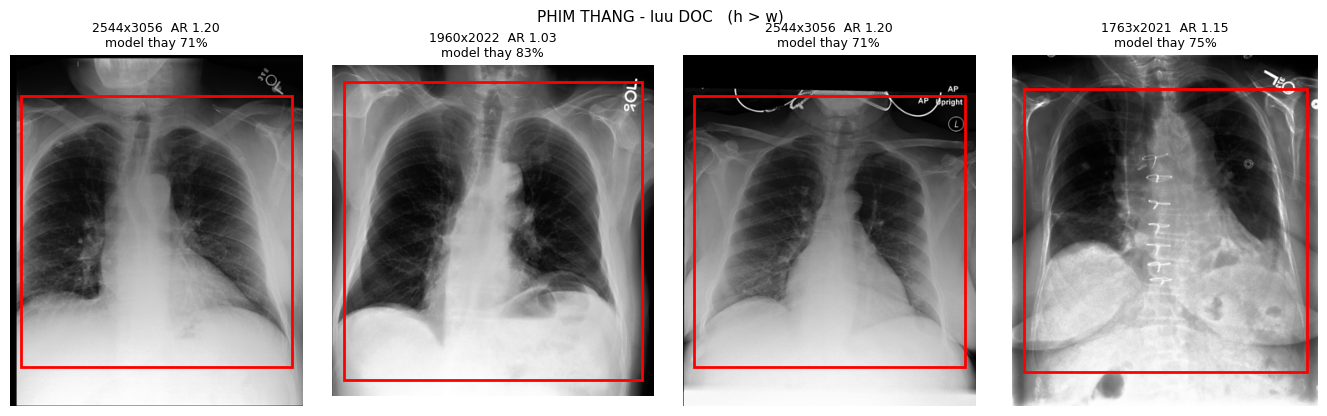

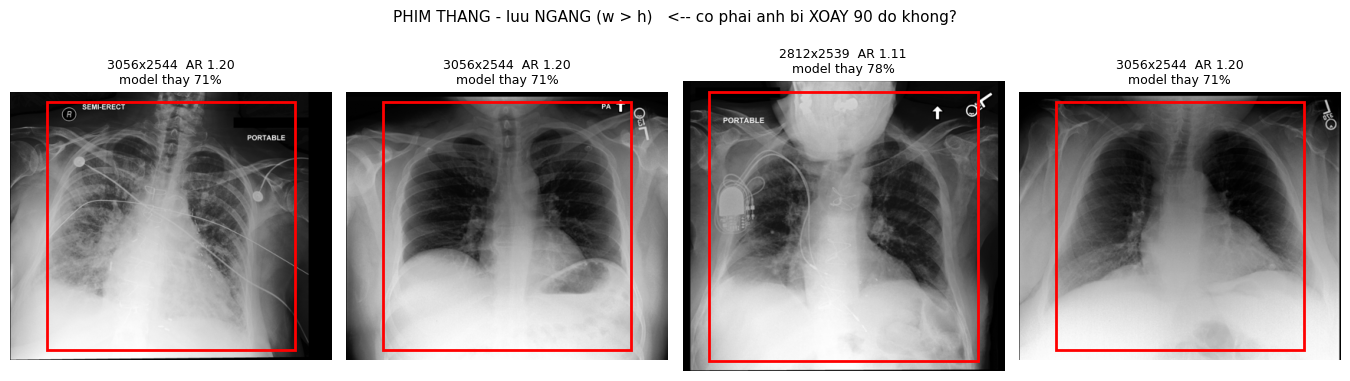


  DOC BANG MAT:
   - neu nhom NGANG la phim nguc bi xoay 90 do  -> loi LUU TRU, sua bang cach xoay
     luc tien xu ly. Re hon F3 rat nhieu, va PHAI sua truoc khi lam F3.
   - neu nhom NGANG la phim nguc dung huong nhung khung rong  -> khong phai loi xoay;
     luc do F1 doc nhu cu va F3 van la buoc tiep theo.


In [6]:
import matplotlib.pyplot as plt

# ---- 1. cross-tab huong x view position ----
_cols = [c for c in ('view_position', 'view_position_resolved', 'view_source')
         if c in man.columns]
SZ2 = SZ.merge(man[['dicom_id']+_cols].drop_duplicates('dicom_id'), on='dicom_id', how='left')
SZ2['huong'] = np.where(np.isclose(SZ2.AR, 1.0, atol=1e-6), 'vuong',
                        np.where(SZ2.portrait, 'doc', 'ngang'))
print('=== PHAN LOAI HUONG DUNG (vuong tach rieng) ===')
print(pd.crosstab(SZ2.view_group, SZ2.huong, margins=True).to_string())
# ---- TAI TRONG ve ty le cohort: mau la 50/50 theo view, cohort thi khong ----
_w = man.view_group.value_counts(normalize=True)
_by = SZ2.groupby('view_group').huong.value_counts(normalize=True).unstack(fill_value=0.0)
_coh = (_by.T*_w.reindex(_by.index)).T.sum()
print()
print('=== TY LE HUONG: mau 50/50 vs TAI TRONG cohort ===')
print(pd.DataFrame({'trong_mau_50_50': SZ2.huong.value_counts(normalize=True),
                    'tai_trong_cohort': _coh}).fillna(0.0)
        .to_string(float_format=lambda v: f'{v:.1%}'))
print(f'  ty le cohort: ' + ' | '.join(f'{k} {v:.1%}' for k, v in _w.items()))
print()
print(f'  ANH NGANG (deu la phim THANG): {_coh.get("ngang", 0):.1%} cua toan cohort')
print(f'    ~ {int(_coh.get("ngang", 0)*len(man)):,} anh.  Day moi la con so dung de danh gia')
print(f'    gia thuyet xoay — KHONG phai ty le trong mau 50/50.')

for c in _cols:
    if SZ2[c].isna().all(): continue
    print()
    print(f'=== huong x {c}  (phim THANG) ===')
    d = SZ2[SZ2.view_group == 'frontal']
    ct = pd.crosstab(d[c], d.huong)
    ct['n'] = ct.sum(1)
    ct['ty_le_ngang'] = (ct.get('ngang', 0)/ct.n).round(3)
    print(ct.sort_values('n', ascending=False).head(8).to_string())
_fr = SZ2[SZ2.view_group == 'frontal']
if 'view_position_resolved' in _cols and not _fr.view_position_resolved.isna().all():
    _by = _fr.groupby('view_position_resolved').huong.apply(lambda s: (s == 'ngang').mean())
    _sp = float(_by.max()-_by.min()) if len(_by) > 1 else 0.0
    print()
    print(f'  chenh ty le NGANG giua cac view position: {_sp:.1%}')
    print('  -> lon  => huong gan voi loai phim (co the la ly do lam sang)')
    print('  -> nho  => huong KHONG gan voi loai phim => nghi ngo loi luu tru/xoay')

# ---- 2. NHIN ANH: 4 doc vs 4 ngang, kem khung do = phan song sot ----
def _path(dic):
    r = man.loc[man.dicom_id == dic].iloc[0]; s = str(int(r.subject_id))
    return os.path.join(DRIVE_IMG, f'p{s[:2]}', f'p{s}', f's{int(r.study_id)}', f'{dic}.jpg')

def _show(dics, title):
    n = len(dics)
    fig, axes = plt.subplots(1, n, figsize=(3.4*n, 4.2))
    for ax, dic in zip(np.atleast_1d(axes), dics):
        im = Image.open(_path(dic)).convert('L')
        w, h = im.size
        side = min(w, h)*MODEL_SIZE/STORE_SIZE          # canh o vuong song sot qua crop1+crop2
        x0, y0 = (w-side)/2, (h-side)/2
        thumb = im.copy(); thumb.thumbnail((420, 420))
        sc = thumb.size[0]/w
        ax.imshow(np.asarray(thumb), cmap='gray')
        ax.add_patch(plt.Rectangle((x0*sc, y0*sc), side*sc, side*sc,
                                   fill=False, edgecolor='red', lw=2))
        ax.set_title(f'{w}x{h}  AR {max(w,h)/min(w,h):.2f}\nmodel thay {(side*side)/(w*h):.0%}',
                     fontsize=9)
        ax.axis('off')
    fig.suptitle(title, fontsize=11); plt.tight_layout(); plt.show()

_rng = np.random.default_rng(SEED)
_doc = _fr[_fr.huong == 'doc'].dicom_id.sample(4, random_state=SEED).tolist()
_ngang = _fr[_fr.huong == 'ngang'].dicom_id.sample(4, random_state=SEED).tolist()
print()
print('=== NHIN ANH: khung DO = phan song sot qua crop1 + crop2 ===')
print('  Phan NGOAI khung do la phan model KHONG BAO GIO nhin thay.')
_show(_doc,   'PHIM THANG - luu DOC   (h > w)')
_show(_ngang, 'PHIM THANG - luu NGANG (w > h)   <-- co phai anh bi XOAY 90 do khong?')
print()
print('  DOC BANG MAT:')
print('   - neu nhom NGANG la phim nguc bi xoay 90 do  -> loi LUU TRU, sua bang cach xoay')
print('     luc tien xu ly. Re hon F3 rat nhieu, va PHAI sua truoc khi lam F3.')
print('   - neu nhom NGANG la phim nguc dung huong nhung khung rong  -> khong phai loi xoay;')
print('     luc do F1 doc nhu cu va F3 van la buoc tiep theo.')

## C6 · Định lượng — AUROC theo hướng *(chỉ chạy nếu `C5` chưa dứt điểm)*

Nếu nhìn ảnh chưa kết luận được, đo bằng số.

**Dùng `AUROC`, không dùng `AP`.** Hai nhóm hướng là hai tập ảnh khác nhau với prevalence khác
nhau, mà `AP` phụ thuộc prevalence — so `AP` giữa hai tập là so hai thứ không cùng thang.
`AUROC` bất biến với prevalence nên so được.

Đo ở **mức ảnh**, dùng per-image prediction mà `nb17` `C5` đã lưu. Mỗi ảnh mang nhãn của study
nó thuộc về — đúng cách nb16 huấn luyện.

### Cổng bắt buộc trước khi tin số

Thứ tự ảnh ở đây phải trùng thứ tự mà `nb17` đã lưu. Kiểm bằng cách **pool lại** per-image với
`0.7/0.3` rồi so Spearman với study-level của nb16. Bài học từ `nb17`: dùng ngưỡng trên **lệch
tuyệt đối** sẽ báo động giả khi khác GPU — nên dùng **thứ hạng**.

**Chi phí:** đọc header `51,880` ảnh val trên Drive, ~`25 img/s` với 32 luồng ⇒ **~35 phút CPU**.
Cache ra `.csv`, chạy lại là đọc cache.

In [7]:
RUN_ORIENT_AUROC = False      # <<< dat True neu C5 chua du de ket luan

if not RUN_ORIENT_AUROC:
    print('C6 chua bat. Chay C5 truoc — nhin anh thuong du de ket luan.')
    print('Dat RUN_ORIENT_AUROC = True neu can so.')
else:
    from sklearn.metrics import roc_auc_score
    NB16_PRED = os.path.join(DATA_DIR, 'label_reliability', 'preds')
    NB17_PRED = os.path.join(DATA_DIR, 'baseline_opt', 'preds')
    PI_PATH = f'{NB17_PRED}/perimg_val_R0_ep2_center518.npy'
    assert os.path.exists(PI_PATH), f'chua co per-image cua nb17: {PI_PATH} -> chay nb17 C5'
    SID_VAL = np.load(f'{NB16_PRED}/sid_val.npy'); Y_VAL = np.load(f'{NB16_PRED}/y_val.npy')
    SUBJ_VAL = np.load(f'{NB16_PRED}/subj_val.npy')
    P16 = np.load(f'{NB16_PRED}/R0_s{SEED}_ep2.npy')
    LABELS = json.load(open(os.path.join(OUT_DIR, 'cohort_meta.json')))['labels']
    C = len(LABELS)
    PI = np.load(PI_PATH)

    # ---- tai dung THU TU anh val cua nb17: sort theo dicom_id, lay dong val ----
    mv = man.sort_values('dicom_id').reset_index(drop=True)
    mv = mv[mv.split == 'val'].reset_index(drop=True)
    assert len(mv) == len(PI), f'so anh val {len(mv)} != per-image cua nb17 {len(PI)}'
    assert np.array_equal(np.sort(mv.study_id.unique()), SID_VAL), 'tap study val khong khop'

    # ---- COÅNG: pool lai phai trung nb16 ve THU HANG ----
    sidi = pd.Series(mv.study_id.to_numpy()).map({s: i for i, s in enumerate(SID_VAL)}).to_numpy()
    isF = (mv.view_group == 'frontal').to_numpy(); isL = ~isF
    def _agg(mask):
        n = np.bincount(sidi[mask], minlength=len(SID_VAL)).astype('float64')
        o = np.zeros((len(SID_VAL), C))
        for j in range(C):
            o[:, j] = np.bincount(sidi[mask], weights=PI[mask, j].astype('float64'),
                                  minlength=len(SID_VAL))/np.maximum(n, 1)
        return o, n > 0
    fr, hf = _agg(isF); la, hl = _agg(isL)
    den = 0.7*hf + 0.3*hl
    rep = (0.7*fr*hf[:, None] + 0.3*la*hl[:, None])/np.maximum(den, 1e-30)[:, None]
    def _sp(u, v):
        ru = pd.Series(u).rank().to_numpy(); rv = pd.Series(v).rank().to_numpy()
        ru -= ru.mean(); rv -= rv.mean()
        return float((ru*rv).sum()/max(np.sqrt((ru**2).sum()*(rv**2).sum()), 1e-30))
    rho = min(_sp(rep[:, j], P16[:, j]) for j in range(C))
    print(f'  COÅNG thu tu anh: Spearman min {rho:.6f}  {"PASS" if rho >= 0.999 else "FAIL"}')
    assert rho >= 0.999, 'thu tu anh khong khop nb17 -> moi so ben duoi vo nghia'

    # ---- doc kich thuoc toan bo anh val ----
    SZV_CSV = f'{SC_DIR}/metrics/val_image_sizes.csv'
    if os.path.exists(SZV_CSV):
        SZV = pd.read_csv(SZV_CSV); print(f'  kich thuoc val <- cache ({len(SZV):,})')
    else:
        t0 = time.time()
        with ThreadPoolExecutor(THREADS) as ex:
            r = list(tqdm(ex.map(_size, [x for x in mv.itertuples()]), total=len(mv),
                          desc='doc header anh val'))
        SZV = pd.DataFrame([(d, s[0], s[1]) for d, s, e in r if s is not None],
                           columns=['dicom_id', 'w', 'h'])
        SZV.to_csv(SZV_CSV, index=False); print(f'  xong sau {(time.time()-t0)/60:.1f} phut')
    mv = mv.merge(SZV, on='dicom_id', how='left')
    ok = mv.w.notna().to_numpy()
    mv['AR'] = mv[['w', 'h']].max(1)/mv[['w', 'h']].min(1)
    mv['huong'] = np.where(np.isclose(mv.AR, 1.0, atol=1e-6), 'vuong',
                           np.where(mv.h > mv.w, 'doc', 'ngang'))
    print(f'  doc duoc {int(ok.sum()):,}/{len(mv):,} | '
          f'{dict(mv.loc[ok, "huong"].value_counts())}')

    # ---- AUROC muc anh theo huong (chi phim THANG) ----
    YI = Y_VAL[sidi]                                    # nhan cua study, gan cho tung anh
    rows = []
    for hg in ('doc', 'ngang'):
        m = ok & isF & (mv.huong == hg).to_numpy()
        if m.sum() < 500: continue
        for j in range(C):
            y = YI[m, j]
            if y.sum() < 20 or y.sum() == m.sum(): continue
            rows.append(dict(huong=hg, label=LABELS[j], n_anh=int(m.sum()),
                             prevalence=float(y.mean()),
                             AUROC=float(roc_auc_score(y, PI[m, j]))))
    A = pd.DataFrame(rows)
    W = A.pivot(index='label', columns='huong', values='AUROC')
    W['delta_doc_tru_ngang'] = W['doc']-W['ngang']
    W['prev_doc'] = A[A.huong == 'doc'].set_index('label').prevalence
    W['prev_ngang'] = A[A.huong == 'ngang'].set_index('label').prevalence
    print()
    print('=== AUROC MUC ANH, phim THANG, theo huong luu tru ===')
    print(W.sort_values('delta_doc_tru_ngang', ascending=False).to_string(
        float_format=lambda v: f'{v:.4f}'))
    _md = float(W.delta_doc_tru_ngang.mean())
    print()
    print(f'  trung binh delta (doc - ngang) tren 13 nhan: {_md:+.4f}')
    if _md > 0.02:
        print('  -> anh NGANG te hon RO RET. Ung ho gia thuyet luu tru xoay.')
        print('     Sua bang cach XOAY luc tien xu ly — re hon F3 va phai lam TRUOC F3.')
    elif abs(_md) <= 0.02:
        print('  -> hai huong tuong duong. KHONG co bang chung model bi thiet boi anh ngang.')
        print('     Gia thuyet xoay khong duoc ung ho; F1/F3 doc nhu cu.')
    else:
        print('  -> anh NGANG lai TOT hon. Bat thuong, xem lai phan loai huong.')
    print()
    print('  LUU Y: day la so sanh giua HAI TAP ANH KHAC NHAU, khong phai so cap.')
    print('  Chenh lech co the den tu khac biet benh nhan/boi canh chu khong tu huong.')
    print('  Cot prevalence in ra de doc duoc muc do lech giua hai tap.')
    A.to_csv(f'{SC_DIR}/metrics/auroc_by_orientation.csv', index=False)
    json.dump(dict(mean_delta_doc_minus_ngang=_md,
                   n_doc=int((ok & isF & (mv.huong == 'doc').to_numpy()).sum()),
                   n_ngang=int((ok & isF & (mv.huong == 'ngang').to_numpy()).sum()),
                   per_label=A.to_dict('records')),
              open(f'{SC_DIR}/metrics/orientation.json', 'w'), indent=1)

C6 chua bat. Chay C5 truoc — nhin anh thuong du de ket luan.
Dat RUN_ORIENT_AUROC = True neu can so.


---

## C7 · **`28.5%` là của KHUNG hay của GIẢI PHẪU?** — sửa `F1`

### Hai kết luận từ `C5`

**Giả thuyết xoay 90° đã đóng.** Nhìn ảnh: cả hai nhóm đều là phim ngực **đúng hướng giải
phẫu**. Nhóm ngang chỉ là khung rộng hơn. Cross-tab khớp: `AP 47.7%` ngang vs `PA 21.0%`, và
các ảnh nhóm ngang mang nhãn `PORTABLE` / `SEMI-ERECT` — phim di động tại giường. **Lý do thu
nhận, không phải lỗi lưu trữ.**

**Nhưng ảnh lộ ra một thứ `F1` không đo được: viền đen.** Nhiều ảnh gốc có dải đen lớn ở rìa
(collimation, vùng ngoài detector). `F1` tính `lost_area` trên **toàn khung file**, nên nếu phần
bị cắt phần lớn là viền đen thì:

```
mat 28.5% KHUNG   !=   mat 28.5% GIAI PHAU
```

Và chỉ phần **giải phẫu** mới là thứ model cần.

### Cell này đo lại

Với mỗi ảnh mẫu: tìm **hộp bao phần không đen**, rồi tính

$$\text{giữ}=\frac{\text{area}(\text{hộp crop}\cap\text{hộp giải phẫu})}{\text{area}(\text{hộp giải phẫu})}$$

Hộp crop là ô vuông giữa cạnh `min(w,h)·518/559` trong toạ độ gốc — đúng phần sống sót qua
`crop1 + crop2`, cùng đại lượng mà `C1`/`C2` báo cáo.

### Cổng `F3` **đọc lại** trên con số mới

Ngưỡng §C0 giữ nguyên (`<10% BỎ` · `10–25% THĂM DÒ` · `>25% ƯU TIÊN`) nhưng áp lên
**`lost_anatomy`**, không phải `lost_frame`. Đây không phải nới cổng sau khi thấy số — mà là
sửa **đại lượng đo** cho đúng thứ cổng vốn định nói.

**Chi phí:** giải mã JPEG ở tỉ lệ `1/8` (PIL `draft`) cho `1,500` ảnh phân tầng ⇒ **~6–12 phút**,
CPU. Đọc pixel nên chậm hơn `F1` (chỉ đọc header).

In [8]:
N_BBOX = 1500          # anh lay mau de do hop bao giai phau
BB_CSV = f'{SC_DIR}/metrics/anatomy_bbox.csv'

def anat_bbox(path, thr_frac=0.03, min_frac=0.02):
    """Hop bao phan KHONG DEN, tra ve trong toa do GOC. draft() giai ma o 1/8 -> nhanh."""
    with Image.open(path) as im:
        W, H = im.size
        im.draft('L', (max(1, W//8), max(1, H//8)))
        a = np.asarray(im.convert('L'), dtype='float32')
    if a.max() <= 0: return 0, 0, W, H, W, H
    t = a.max()*thr_frac
    rmask = (a > t).mean(1) > min_frac
    cmask = (a > t).mean(0) > min_frac
    if not rmask.any() or not cmask.any(): return 0, 0, W, H, W, H
    r0, r1 = int(np.argmax(rmask)), int(len(rmask)-np.argmax(rmask[::-1]))
    c0, c1 = int(np.argmax(cmask)), int(len(cmask)-np.argmax(cmask[::-1]))
    sy, sx = H/a.shape[0], W/a.shape[1]
    return int(c0*sx), int(r0*sy), int(c1*sx), int(r1*sy), W, H

if os.path.exists(BB_CSV):
    BB = pd.read_csv(BB_CSV); print(f'bbox <- cache ({len(BB):,})')
else:
    _s = (SZ2.groupby(['view_group', 'huong'], group_keys=False)
              .apply(lambda d: d.sample(min(len(d), max(60, N_BBOX//6)), random_state=SEED))
              .reset_index(drop=True))
    print(f'lay mau {len(_s):,} anh, phan tang theo (view_group x huong):')
    print('  ' + str(dict(_s.groupby(['view_group', 'huong']).size())))
    def _one(r):
        try:
            return (r.dicom_id,)+anat_bbox(_path(r.dicom_id))
        except Exception:
            return (r.dicom_id, None, None, None, None, None, None)
    t0 = time.time()
    with ThreadPoolExecutor(THREADS) as ex:
        res = list(tqdm(ex.map(_one, [r for r in _s.itertuples()]), total=len(_s), desc='hop bao'))
    BB = pd.DataFrame([r for r in res if r[1] is not None],
                      columns=['dicom_id', 'x0', 'y0', 'x1', 'y1', 'W', 'H'])
    BB.to_csv(BB_CSV, index=False)
    print(f'  xong {len(BB):,} anh sau {(time.time()-t0)/60:.1f} phut')

BB = BB.merge(SZ2[['dicom_id', 'view_group', 'huong', 'AR', 'lost_area']], on='dicom_id')
BB['aw'] = BB.x1-BB.x0; BB['ah'] = BB.y1-BB.y0
BB['frac_khung_la_giai_phau'] = (BB.aw*BB.ah)/(BB.W*BB.H)
BB['AR_giai_phau'] = BB[['aw', 'ah']].max(1)/BB[['aw', 'ah']].min(1).clip(lower=1)

# ---- giao cua hop crop voi hop giai phau ----
_side = BB[['W', 'H']].min(1)*MODEL_SIZE/STORE_SIZE
_cx0 = (BB.W-_side)/2; _cy0 = (BB.H-_side)/2
_ix = (np.minimum(_cx0+_side, BB.x1)-np.maximum(_cx0, BB.x0)).clip(lower=0)
_iy = (np.minimum(_cy0+_side, BB.y1)-np.maximum(_cy0, BB.y0)).clip(lower=0)
BB['giu_giai_phau'] = (_ix*_iy)/(BB.aw*BB.ah).clip(lower=1)
BB['mat_giai_phau'] = 1-BB.giu_giai_phau
BB.to_csv(BB_CSV.replace('.csv', '_full.csv'), index=False)

print()
print('=== KHUNG vs GIAI PHAU ===')
Q2 = BB.groupby('view_group').agg(
    n=('AR', 'size'),
    AR_khung=('AR', 'median'), AR_giai_phau=('AR_giai_phau', 'median'),
    khung_la_giai_phau=('frac_khung_la_giai_phau', 'median'),
    mat_KHUNG=('lost_area', 'median'), mat_GIAI_PHAU=('mat_giai_phau', 'median'))
print(Q2.to_string(float_format=lambda v: f'{v:.4f}'))
_wv = man.view_group.value_counts(normalize=True)
_mk = float((BB.groupby('view_group').lost_area.median()*_wv.reindex(Q2.index)).sum())
_mg = float((BB.groupby('view_group').mat_giai_phau.median()*_wv.reindex(Q2.index)).sum())
print()
print(f'  TAI TRONG COHORT:  mat KHUNG {_mk:.1%}  ->  mat GIAI PHAU {_mg:.1%}')
print(f'  phan khung la giai phau (trung vi): {BB.frac_khung_la_giai_phau.median():.1%}')
print(f'  AR: khung {BB.AR.median():.3f} -> giai phau {BB.AR_giai_phau.median():.3f}')
print()
print('  --- theo huong ---')
print(BB.groupby('huong').agg(n=('AR', 'size'), mat_KHUNG=('lost_area', 'median'),
                              mat_GIAI_PHAU=('mat_giai_phau', 'median'),
                              khung_la_giai_phau=('frac_khung_la_giai_phau', 'median')
                              ).to_string(float_format=lambda v: f'{v:.4f}'))

print()
print('=== COÅNG F3 DOC LAI tren MAT GIAI PHAU ===')
V2 = 'BO' if _mg < 0.10 else ('THAM DO' if _mg <= 0.25 else 'UU TIEN')
print(f'  truoc (mat KHUNG)      {_mk:.1%}  ->  {VERDICT}')
print(f'  sau   (mat GIAI PHAU)  {_mg:.1%}  ->  {V2}')
if V2 != VERDICT:
    print()
    print(f'  ! VERDICT DOI: {VERDICT} -> {V2}')
    print('    F1 do phan tram cua KHUNG FILE. Nhung anh goc co san vien den/collimation,')
    print('    nen phan bi cat phan lon KHONG phai giai phau. Day la sua DAI LUONG DO cho dung')
    print('    thu cong von dinh noi — khong phai noi nguong sau khi thay so.')
print({'BO': '  -> F3 KHONG dang lam. Phan giai phau bi mat qua nho.',
       'THAM DO': '  -> F3 exploratory, uu tien thap.',
       'UU TIEN': '  -> F3 van dang gia.'}[V2])

print()
print('=== HUONG: gia thuyet XOAY 90 do — DONG ===')
print('  Nhin anh o C5: ca hai nhom deu la phim nguc DUNG huong giai phau.')
if 'view_position_resolved' in SZ2.columns:
    _fr2 = SZ2[SZ2.view_group == 'frontal']
    for _vp in ('AP', 'PA'):
        _d = _fr2[_fr2.view_position_resolved == _vp]
        if len(_d):
            print(f'    {_vp}: {(_d.huong == "ngang").mean():.1%} ngang  (n={len(_d):,})')
print('  -> huong gan voi loai phim (AP di dong dung khung rong). LY DO THU NHAN,')
print('     khong phai loi luu tru. Khong can xoay lai o tien xu ly.')
print()
print('  Anh huong toi co che cua F3: phan bi cat khac nhau theo huong —')
print('    doc   -> tren + duoi (dinh phoi, goc suon hoanh)')
print('    ngang -> trai + phai (thanh nguc ben, suon ben)')
print('  Fracture (suon vong quanh) chiu ca hai; Pleural_Other (goc suon hoanh) chu yeu o nhom doc.')

json.dump(dict(n_bbox=int(len(BB)),
               lost_frame_cohort=_mk, lost_anatomy_cohort=_mg,
               frac_frame_is_anatomy=float(BB.frac_khung_la_giai_phau.median()),
               ar_frame=float(BB.AR.median()), ar_anatomy=float(BB.AR_giai_phau.median()),
               verdict_frame=VERDICT, verdict_anatomy=V2,
               rotation_hypothesis='DONG — nhin anh o C5, ca hai huong deu dung giai phau; '
                                   'huong gan voi AP/PA (phim di dong khung rong)',
               by_view=Q2.reset_index().to_dict('records')),
          open(f'{SC_DIR}/metrics/f1_anatomy_corrected.json', 'w'), indent=1)
print()
print(f'-> {SC_DIR}/metrics/f1_anatomy_corrected.json')

bbox <- cache (1,015)

=== KHUNG vs GIAI PHAU ===
              n  AR_khung  AR_giai_phau  khung_la_giai_phau  mat_KHUNG  mat_GIAI_PHAU
view_group                                                                           
frontal     572    1.2013        1.2010              1.0000     0.2852         0.2663
lateral     443    1.2013        1.1885              0.9802     0.2852         0.2285

  TAI TRONG COHORT:  mat KHUNG 28.5%  ->  mat GIAI PHAU 25.4%
  phan khung la giai phau (trung vi): 99.1%
  AR: khung 1.201 -> giai phau 1.195

  --- theo huong ---
         n  mat_KHUNG  mat_GIAI_PHAU  khung_la_giai_phau
huong                                                   
doc    500     0.2852         0.2680              0.9843
ngang  287     0.2852         0.2740              0.9969
vuong  228     0.1413         0.1413              1.0000

=== COÅNG F3 DOC LAI tren MAT GIAI PHAU ===
  truoc (mat KHUNG)      28.5%  ->  UU TIEN
  sau   (mat GIAI PHAU)  25.4%  ->  UU TIEN
  -> F3 van dang gia.


---

## C8 · `mất_giải_phẫu` nhạy tới đâu với ngưỡng đen?

`C7` chạy ở `thr_frac = 0.03`, tức mọi pixel `> 7.6/255` được tính là **giải phẫu**. Vùng ngoài
collimator sau nén JPEG thường nằm ở `5–20`, nên ngưỡng này có thể **quá lỏng** — và mọi sai lệch
theo hướng đó chỉ kéo `mất_giải_phẫu` **xuống**.

Dấu hiệu đáng ngờ trong `C7`: trung vị `khung_là_giải_phẫu` của `frontal` ra **đúng bằng
`1.0000`** — tức trên nửa số ảnh frontal không phát hiện viền nào, ngược với ấn tượng mắt ở `C5`.

Và `25.4%` chỉ hơn ngưỡng `UU TIEN` đúng **`0.4 pp`**. Verdict đang treo trên một tham số chưa
được hiệu chuẩn.

### Cell này làm gì

Giải mã **một lần** mỗi ảnh (cùng mẫu `C7`, đọc `dicom_id` từ CSV đã cache nên **so cặp**), rồi
tính hộp bao ở **tất cả** ngưỡng — nên chi phí vẫn là `~1.2 phút`, không nhân lên.

Kèm một chẩn đoán để **chọn** ngưỡng thay vì đoán: cường độ thật của vành ngoài `1%` khung, so
với `max` của ảnh. Nếu vành ngoài nằm ở `~2%` của max thì `thr = 0.03` là hợp lý; nếu ở `~8%` thì
nó đang bỏ sót viền.

**Không** cell nào đổi verdict tự động — bảng in ra `mat_GIAI_PHAU` và verdict cho từng ngưỡng để
đọc bằng mắt.

In [9]:
THR_SWEEP = [0.03, 0.06, 0.10, 0.15]
SW_CSV = f'{SC_DIR}/metrics/anatomy_bbox_sweep.csv'

def bbox_multi(path, thrs, min_frac=0.02):
    """Giai ma MOT lan, tra ve hop bao cho MOI nguong + cuong do vanh ngoai."""
    with Image.open(path) as im:
        W, H = im.size
        im.draft('L', (max(1, W//8), max(1, H//8)))
        a = np.asarray(im.convert('L'), dtype='float32')
    mx = float(a.max())
    k = max(1, int(round(0.01*min(a.shape))))          # vanh ngoai 1% khung
    ring = np.concatenate([a[:k].ravel(), a[-k:].ravel(), a[:, :k].ravel(), a[:, -k:].ravel()])
    out = [W, H, mx, float(np.median(ring)), float(np.percentile(ring, 90))]
    sy, sx = H/a.shape[0], W/a.shape[1]
    for t in thrs:
        rm = (a > mx*t).mean(1) > min_frac; cm = (a > mx*t).mean(0) > min_frac
        if mx <= 0 or not rm.any() or not cm.any():
            out += [0, 0, W, H]; continue
        r0, r1 = int(np.argmax(rm)), int(len(rm)-np.argmax(rm[::-1]))
        c0, c1 = int(np.argmax(cm)), int(len(cm)-np.argmax(cm[::-1]))
        out += [int(c0*sx), int(r0*sy), int(c1*sx), int(r1*sy)]
    return out

_COLS = ['W', 'H', 'mx', 'ring_med', 'ring_p90'] + \
        [f'{p}{t}' for t in THR_SWEEP for p in ('x0_', 'y0_', 'x1_', 'y1_')]
if os.path.exists(SW_CSV):
    SW = pd.read_csv(SW_CSV); print(f'sweep <- cache ({len(SW):,})')
else:
    _ids = pd.read_csv(BB_CSV).dicom_id.tolist()       # DUNG MAU cua C7 -> so CAP
    print(f'{len(_ids):,} anh (dung mau C7), {len(THR_SWEEP)} nguong, giai ma 1 lan')
    def _one_sw(d):
        try:    return [d]+bbox_multi(_path(d), THR_SWEEP)
        except Exception: return None
    t0 = time.time()
    with ThreadPoolExecutor(THREADS) as ex:
        res = [r for r in tqdm(ex.map(_one_sw, _ids), total=len(_ids), desc='quet nguong') if r]
    SW = pd.DataFrame(res, columns=['dicom_id']+_COLS)
    SW.to_csv(SW_CSV, index=False)
    print(f'  xong {len(SW):,} anh sau {(time.time()-t0)/60:.1f} phut')

SW = SW.merge(SZ2[['dicom_id', 'view_group', 'huong', 'lost_area']], on='dicom_id')
print()
print('=== CHAN DOAN: vanh ngoai 1% khung sang bao nhieu so voi max? ===')
_rd = pd.DataFrame(dict(ty_le_max_trung_vi=SW.ring_med/SW.mx.clip(lower=1),
                        ty_le_max_p90=SW.ring_p90/SW.mx.clip(lower=1),
                        view_group=SW.view_group)).groupby('view_group').median()
print(_rd.to_string(float_format=lambda v: f'{v:.4f}'))
_rq = (SW.ring_med/SW.mx.clip(lower=1))
print(f'  toan mau: trung vi {_rq.median():.4f} | p75 {_rq.quantile(.75):.4f} | p90 {_rq.quantile(.9):.4f}')
print(f'  -> nguong nen NAM TREN cuong do vanh ngoai. thr = 0.03 '
      f'{"HOP LY" if _rq.quantile(.75) < 0.03 else "CO THE DANG BO SOT vien"}.')

_wv = man.view_group.value_counts(normalize=True)
print()
print('=== MAT GIAI PHAU theo NGUONG (tai trong cohort) ===')
rows = []
for t in THR_SWEEP:
    aw = (SW[f'x1_{t}']-SW[f'x0_{t}']).clip(lower=1); ah = (SW[f'y1_{t}']-SW[f'y0_{t}']).clip(lower=1)
    side = SW[['W', 'H']].min(1)*MODEL_SIZE/STORE_SIZE
    cx0 = (SW.W-side)/2; cy0 = (SW.H-side)/2
    ix = (np.minimum(cx0+side, SW[f'x1_{t}'])-np.maximum(cx0, SW[f'x0_{t}'])).clip(lower=0)
    iy = (np.minimum(cy0+side, SW[f'y1_{t}'])-np.maximum(cy0, SW[f'y0_{t}'])).clip(lower=0)
    mat = 1-(ix*iy)/(aw*ah)
    khung = (aw*ah)/(SW.W*SW.H)
    g = pd.DataFrame(dict(view_group=SW.view_group, mat=mat, khung=khung)).groupby('view_group')
    coh = float((g.mat.median()*_wv.reindex(g.mat.median().index)).sum())
    rows.append(dict(thr=t, khung_la_giai_phau=float(khung.median()),
                     mat_frontal=float(g.mat.median().get('frontal', np.nan)),
                     mat_lateral=float(g.mat.median().get('lateral', np.nan)),
                     mat_GIAI_PHAU_cohort=coh,
                     verdict='BO' if coh < 0.10 else ('THAM DO' if coh <= 0.25 else 'UU TIEN')))
R = pd.DataFrame(rows)
print(R.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print(f'  (mat KHUNG, khong phu thuoc nguong: {float(SW.lost_area.median()):.4f})')

print()
print('=== DOC ===')
_v = R.verdict.unique().tolist()
if len(_v) == 1:
    print(f'  MOI nguong deu cho {_v[0]} -> verdict BEN, khong phu thuoc tham so nay.')
else:
    print(f'  verdict DOI theo nguong: {dict(zip(R.thr, R.verdict))}')
    print('  -> 25.4% cua C7 KHONG ben. Phai chot nguong bang chan doan vanh ngoai o tren')
    print('     TRUOC khi dung con so nay bien minh cho bat ky arm FOV nao.')
_d = float(R.mat_GIAI_PHAU_cohort.max()-R.mat_GIAI_PHAU_cohort.min())
print(f'  bien do do nguong: {_d:.4f} ({_d*100:.1f} pp).  Khoang cach toi nguong 25%: '
      f'{abs(R.mat_GIAI_PHAU_cohort.iloc[0]-0.25)*100:.1f} pp')

json.dump(dict(thr_sweep=THR_SWEEP, rows=R.to_dict('records'),
               ring_med_over_max=dict(median=float(_rq.median()), p75=float(_rq.quantile(.75)),
                                      p90=float(_rq.quantile(.9))),
               verdict_stable=bool(len(_v) == 1)),
          open(f'{SC_DIR}/metrics/f1_threshold_sweep.json', 'w'), indent=1)
print()
print(f'-> {SC_DIR}/metrics/f1_threshold_sweep.json')

sweep <- cache (1,015)

=== CHAN DOAN: vanh ngoai 1% khung sang bao nhieu so voi max? ===
            ty_le_max_trung_vi  ty_le_max_p90
view_group                                   
frontal                 0.2196         0.9608
lateral                 0.0706         0.9451
  toan mau: trung vi 0.1333 | p75 0.3255 | p90 0.4925
  -> nguong nen NAM TREN cuong do vanh ngoai. thr = 0.03 CO THE DANG BO SOT vien.

=== MAT GIAI PHAU theo NGUONG (tai trong cohort) ===
   thr  khung_la_giai_phau  mat_frontal  mat_lateral  mat_GIAI_PHAU_cohort verdict
0.0300              0.9906       0.2663       0.2285                0.2541 UU TIEN
0.0600              0.9874       0.2660       0.2241                0.2525 UU TIEN
0.1000              0.9843       0.2656       0.2178                0.2502 UU TIEN
0.1500              0.9802       0.2649       0.2140                0.2485 THAM DO
  (mat KHUNG, khong phu thuoc nguong: 0.2852)

=== DOC ===
  verdict DOI theo nguong: {0.03: 'UU TIEN', 0.06: 'UU TIEN', 